# RQ2 results: maintenance purpose of skill releases and security flag transitions

**RQ2:** How does the maintenance purpose of a release relate to flag-inducing and flag-fixing transitions?

Each RQ1 key point (one change inside a version pair) has one **Extended Swanson** category
(Swanson 1976; Hindle et al. 2008): *Corrective, Adaptive, Perfective, Implementation, Non-functional*.
A pair carries every category its key points have, plus one dominant category.

Following Hindle et al. (MSR 2008), results are given as:
1. the overall distribution of categories (their Fig. 4),
2. the distribution per group, here the transition strata *introduced / fixed / no change* instead of projects (their Fig. 3 and Table 8),
3. which kinds of change make up each category (their Fig. 1 to 2, here RQ1 themes x RQ2 categories),

then, as in `rq1_results.ipynb`, Fisher exact tests of each category against the *no change* baseline.

**Inputs:** the RQ2 labelling files (`RQ2_DIR`) and `clawhub_pair_status.parquet` for each pair's ClawScan status.
The status file is only joined here, after labelling. **Outputs:** `results/rq2/*.csv` and `results/rq2/figs/*.png`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

ROOT = Path(".")
RQ2_DIR = ROOT / "rq2_labelling"     # folder holding the RQ2 labelling files (searched recursively)
STATUS_PATH = Path(r"C:\Users\HP\Desktop\aise_script\clawhub_pair_status.parquet")
OUT = ROOT / "results" / "rq2"
FIGS = OUT / "figs"
FIGS.mkdir(parents=True, exist_ok=True)

CATS = ["Corrective", "Adaptive", "Perfective", "Implementation", "Non-functional"]   # Hindle's order
STRATA = ["introduced", "fixed", "no change"]
BASELINE = "no change"
ALPHA = 0.05
# Stratum pool sizes at the Phase 2 draw (same as rq1_results.ipynb), used to weight Phase 2 to the population.
POOL_N = {"fixed": 10645, "introduced": 14233, "no change": 67816}
COLORS = {"Corrective": "#c0504d", "Adaptive": "#4f81bd", "Perfective": "#9bbb59",
          "Implementation": "#f79646", "Non-functional": "#8064a2"}
SCOL = {"introduced": "#c0504d", "fixed": "#4f81bd", "no change": "#9a9a9a"}
pd.set_option("display.max_rows", 200, "display.max_colwidth", 90)


def save(df, name, index=True, fmt=None):
    df.to_csv(OUT / f"{name}.csv", index=index, encoding="utf-8-sig")
    display(df.style.format(fmt, na_rep="-") if fmt else df)


def find(name):
    hits = sorted(RQ2_DIR.rglob(name))
    if not hits:
        raise FileNotFoundError(f"{name} not found under {RQ2_DIR.resolve()}")
    return hits[0]


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def bh(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    ranked = p[order] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(q)
    out[order] = np.minimum(q, 1)
    return out

## 1. Load labels and join the transition stratum

In [2]:
kp1 = pd.read_csv(find("phase1_all_rq2_keypoints.csv"), encoding="utf-8-sig", dtype=str).fillna("")
kp2 = pd.read_csv(find("phase2_rq2_keypoints.csv"), encoding="utf-8-sig", dtype=str).fillna("")
kp1["phase"], kp2["phase"] = "phase 1", "phase 2"
kp = pd.concat([kp1, kp2], ignore_index=True)

# use the agreed label where the coders filled it in, otherwise the first-pass label
kp["category"] = kp["agreed_category"].where(kp["agreed_category"].str.strip() != "", kp["rq2_category"])
print("agreed labels used:", int((kp["agreed_category"].str.strip() != "").sum()), "of", len(kp))

st = pd.read_parquet(STATUS_PATH, columns=["skill_slug", "version", "prev_version",
                                           "llm_normalized_status", "prev_llm_normalized_status"])
st = st.dropna(subset=["prev_version"])
st["pair_id"] = st["skill_slug"] + "@" + st["prev_version"].astype(str) + "->" + st["version"].astype(str)
FLAG = {"suspicious", "malicious"}
def stratum(a, b):
    if (a == "clean" and b == "clean") or (a in FLAG and b in FLAG): return "no change"
    if a == "clean" and b in FLAG: return "introduced"
    if a in FLAG and b == "clean": return "fixed"
    return None
st["stratum"] = [stratum(a, b) for a, b in zip(st["prev_llm_normalized_status"], st["llm_normalized_status"])]
kp = kp.merge(st[["pair_id", "stratum"]].drop_duplicates("pair_id"), on="pair_id", how="left")
assert kp["stratum"].notna().all(), "some pairs have no stratum"

lab = kp[kp["category"] != "excluded"].copy()
summary = (kp.assign(labelled=kp["category"] != "excluded")
             .groupby("phase").agg(pairs=("pair_id", "nunique"), key_points=("pair_id", "size"),
                                    labelled_key_points=("labelled", "sum")))
summary["labelled_pairs"] = lab.groupby("phase")["pair_id"].nunique()
save(summary, "rq2_summary")
save(pd.crosstab(lab["phase"], lab["rq2_confidence"]), "rq2_confidence")

agreed labels used: 0 of 3638


,pairs,key_points,labelled_key_points,labelled_pairs
phase,,,,
phase 1,400,862,809,347
phase 2,1300,2776,2640,1164


rq2_confidence,high,low,medium
phase,,,
phase 1,717,31,61
phase 2,617,51,1972


## 2. Overall distribution of maintenance categories

Three views, as in Hindle et al.: share of **pairs** that contain each category (a pair can have several,
so shares add up to more than 100%), the share of **key points**, and each pair's **dominant** category.

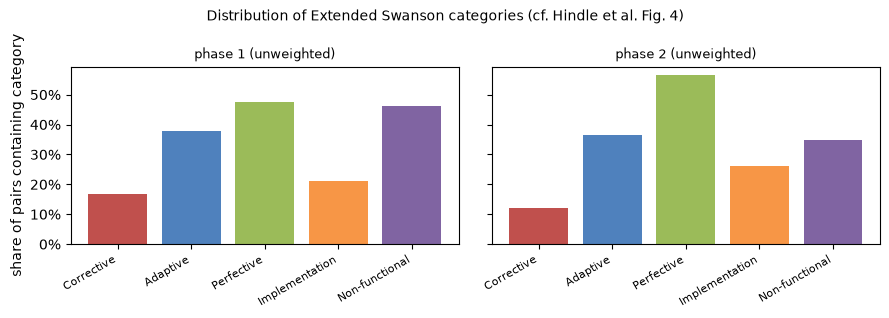

In [3]:
def pair_presence(d):
    return (pd.crosstab(d["pair_id"], d["category"]) > 0).astype(int).reindex(columns=CATS, fill_value=0)

def dominant(d):
    order = ["Corrective", "Implementation", "Adaptive", "Perfective", "Non-functional"]   # tie-break
    cnt = pd.crosstab(d["pair_id"], d["category"]).reindex(columns=order, fill_value=0)
    return cnt.apply(lambda r: r.idxmax(), axis=1)     # idxmax keeps the first maximum in tie-break order

rows = []
for ph, d in lab.groupby("phase"):
    pres = pair_presence(d); n = len(pres)
    kpn = d["category"].value_counts().reindex(CATS, fill_value=0)
    dom = dominant(d).value_counts().reindex(CATS, fill_value=0)
    for c in CATS:
        rows.append({"phase": ph, "category": c, "pairs_with": int(pres[c].sum()), "pairs_share": pres[c].mean(),
                     "key_points": int(kpn[c]), "key_point_share": kpn[c] / kpn.sum(),
                     "dominant_pairs": int(dom[c]), "dominant_share": dom[c] / n})
overall = pd.DataFrame(rows).set_index(["phase", "category"])
save(overall, "rq2_overall", fmt={"pairs_share": "{:.1%}", "key_point_share": "{:.1%}", "dominant_share": "{:.1%}"})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, ph in zip(axes, ["phase 1", "phase 2"]):
    v = overall.loc[ph, "pairs_share"].reindex(CATS)
    ax.bar(range(len(CATS)), v, color=[COLORS[c] for c in CATS])
    ax.set_xticks(range(len(CATS))); ax.set_xticklabels(CATS, rotation=30, ha="right", fontsize=8)
    ax.set_title(f"{ph} (unweighted)", fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[0].set_ylabel("share of pairs containing category")
fig.suptitle("Distribution of Extended Swanson categories (cf. Hindle et al. Fig. 4)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "rq2_overall.png", dpi=200); plt.show()

In [4]:
# number of different categories per pair
ncat = lab.groupby(["phase", "pair_id"])["category"].nunique().rename("categories_per_pair").reset_index()
t = pd.crosstab(ncat["categories_per_pair"], ncat["phase"])
save(t, "rq2_categories_per_pair")
print("mean categories per pair:", ncat.groupby("phase")["categories_per_pair"].mean().round(2).to_dict())

phase,phase 1,phase 2
categories_per_pair,,
1,166,654
2,130,302
3,45,160
4,4,44
5,2,4


mean categories per pair: {'phase 1': 1.69, 'phase 2': 1.66}


## 3. Phase 2: categories by transition stratum

Phase 2 is the measurement sample (95% confidence, 5% margin per stratum). `share` is the share of pairs in
the stratum that contain the category, with a 95% Wilson interval. `all (weighted)` weights strata to their
population size among pairs with changes, as in `rq1_results.ipynb`. This is the analogue of Hindle et al.'s
Table 8 (large vs. small commits), with strata in place of commit size.

,population weight
introduced,15.8%
fixed,11.8%
no change,72.3%


stratum,introduced,fixed,no change,all (weighted)
category,,,,
Corrective,"9.2% [6.7%, 12.5%]","16.0% [12.7%, 20.0%]","11.2% [8.4%, 14.7%]",11.4%
Adaptive,"39.8% [35.1%, 44.7%]","41.5% [36.7%, 46.5%]","28.4% [24.1%, 33.1%]",31.7%
Perfective,"56.4% [51.4%, 61.2%]","51.0% [46.1%, 56.0%]","62.2% [57.3%, 66.9%]",60.0%
Implementation,"31.4% [27.0%, 36.1%]","17.8% [14.3%, 21.9%]","29.4% [25.1%, 34.2%]",28.4%
Non-functional,"37.5% [32.9%, 42.4%]","32.7% [28.3%, 37.6%]","33.9% [29.3%, 38.7%]",34.3%
pairs (n),392,388,384,1164


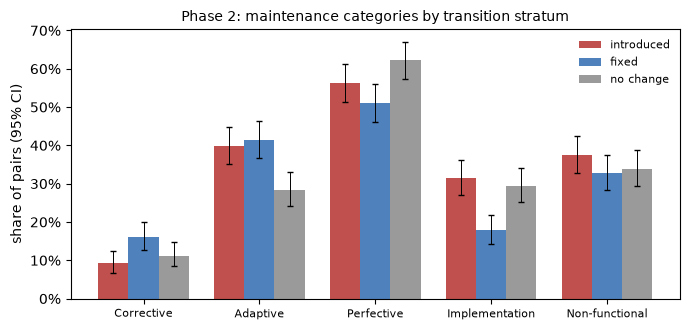

In [5]:
p2 = lab[lab["phase"] == "phase 2"]
p2_pairs = p2.drop_duplicates("pair_id").set_index("pair_id")["stratum"]
pres2 = pair_presence(p2).loc[p2_pairs.index]

# weights: pool size x share of drawn pairs that had labelled changes
drawn = kp[kp["phase"] == "phase 2"].drop_duplicates("pair_id").groupby("stratum").size()
inc = p2_pairs.value_counts()
pop = pd.Series({s: POOL_N[s] * inc.get(s, 0) / drawn.get(s, 1) for s in STRATA})
W = pop / pop.sum()
display(W.rename("population weight").to_frame().style.format("{:.1%}"))

long, wide, ci_tab = [], {}, {}
for s in STRATA:
    m = p2_pairs == s; n = int(m.sum())
    for c in CATS:
        k = int(pres2.loc[m, c].sum()); lo, hi = wilson(k, n)
        long.append({"stratum": s, "category": c, "pairs": k, "n": n, "share": k / n, "ci_low": lo, "ci_high": hi})
long = pd.DataFrame(long)
share = long.pivot(index="category", columns="stratum", values="share").reindex(CATS)[STRATA]
share["all (weighted)"] = sum(share[s] * W[s] for s in STRATA)
long.to_csv(OUT / "rq2_p2_by_stratum_long.csv", index=False, encoding="utf-8-sig")
tab = long.assign(txt=lambda d: d.apply(lambda r: f"{r.share:.1%} [{r.ci_low:.1%}, {r.ci_high:.1%}]", axis=1)
                  ).pivot(index="category", columns="stratum", values="txt").reindex(CATS)[STRATA]
tab["all (weighted)"] = share["all (weighted)"].map("{:.1%}".format)
tab.loc["pairs (n)"] = [str(int((p2_pairs == s).sum())) for s in STRATA] + [str(len(p2_pairs))]
save(tab, "rq2_p2_by_stratum")

fig, ax = plt.subplots(figsize=(7, 3.4))
h = 0.26
for i, s in enumerate(STRATA):
    d = long[long["stratum"] == s].set_index("category").reindex(CATS)
    x = np.arange(len(CATS)) + (i - 1) * h
    ax.bar(x, d["share"], width=h, color=SCOL[s], label=s)
    ax.errorbar(x, d["share"], yerr=[d["share"] - d["ci_low"], d["ci_high"] - d["share"]], fmt="none", ecolor="k", lw=0.7, capsize=2)
ax.set_xticks(range(len(CATS))); ax.set_xticklabels(CATS, fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("share of pairs (95% CI)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Phase 2: maintenance categories by transition stratum", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "rq2_p2_by_stratum.png", dpi=200); plt.show()

,introduced,fixed,no change
category,,,
Corrective,12.7%,16.5%,70.8%
Adaptive,19.8%,15.5%,64.7%
Perfective,14.9%,10.1%,75.1%
Implementation,17.5%,7.4%,75.1%
Non-functional,17.3%,11.3%,71.4%


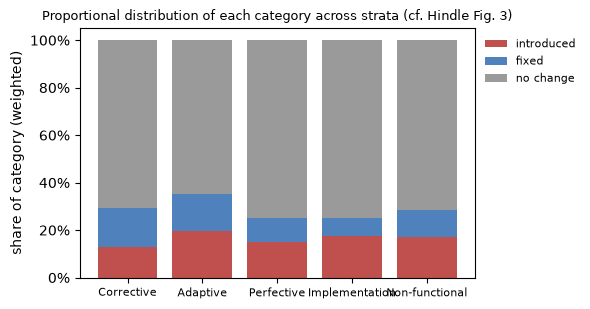

In [6]:
# Hindle et al. Fig. 3 analogue: for each category, how its pairs split across strata
# (weighted to the population so the split reflects ClawHub, not the sampling design)
contrib = pd.DataFrame({s: share[s] * W[s] for s in STRATA}).reindex(CATS)
contrib = contrib.div(contrib.sum(axis=1), axis=0)
save(contrib, "rq2_p2_category_split_by_stratum", fmt="{:.1%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
bottom = np.zeros(len(CATS))
for s in STRATA:
    ax.bar(range(len(CATS)), contrib[s], bottom=bottom, color=SCOL[s], label=s)
    bottom += contrib[s].values
ax.set_xticks(range(len(CATS))); ax.set_xticklabels(CATS, fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("share of category (weighted)"); ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
ax.set_title("Proportional distribution of each category across strata (cf. Hindle Fig. 3)", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "rq2_p2_category_split.png", dpi=200); plt.show()

In [7]:
# dominant category by stratum
dom2 = dominant(p2).rename("dominant").to_frame().join(p2_pairs)
dt = pd.crosstab(dom2["dominant"], dom2["stratum"]).reindex(index=CATS, columns=STRATA, fill_value=0)
dts = dt / dt.sum()
dts["all (weighted)"] = sum(dts[s] * W[s] for s in STRATA)
save(dts, "rq2_p2_dominant_by_stratum", fmt="{:.1%}")
chi2, p, dof, _ = stats.chi2_contingency(dt)
print(f"dominant category x stratum: chi2 = {chi2:.2f}, df = {dof}, p = {p:.4g}")

stratum,introduced,fixed,no change,all (weighted)
dominant,,,,
Corrective,6.9%,14.2%,9.1%,9.4%
Adaptive,23.5%,30.4%,17.2%,19.7%
Perfective,33.9%,31.7%,43.5%,40.6%
Implementation,21.9%,11.1%,18.0%,17.8%
Non-functional,13.8%,12.6%,12.2%,12.5%


dominant category x stratum: chi2 = 47.58, df = 8, p = 1.186e-07


### 3b. Association with flag transitions

Fisher exact test per category: share of pairs containing it in *introduced* (or *fixed*) vs. *no change*.
Odds ratios use a Haldane correction; q values are Benjamini-Hochberg adjusted within each comparison.
Two robustness checks: `q_without_low` repeats the test without the low-confidence (poor-fit) key points,
and the `phase1_*` columns repeat it on Phase 1, where every purpose-dependent label was checked by hand
(balanced sample, so read it as a replication of direction, not of prevalence).

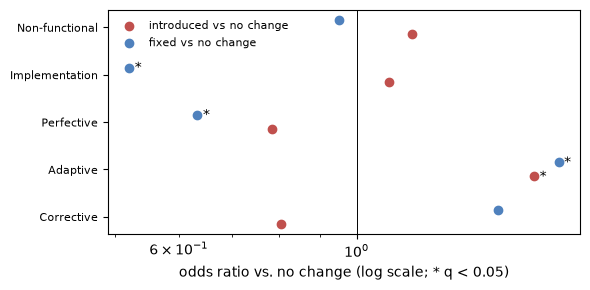

In [8]:
def assoc(d):
    pairs = d.drop_duplicates("pair_id").set_index("pair_id")["stratum"]
    pres = pair_presence(d).loc[pairs.index]
    rows = []
    for grp in [s for s in STRATA if s != BASELINE]:
        for c in CATS:
            a = int(pres.loc[pairs == grp, c].sum()); na = int((pairs == grp).sum())
            b = int(pres.loc[pairs == BASELINE, c].sum()); nb = int((pairs == BASELINE).sum())
            _, pv = stats.fisher_exact([[a, na - a], [b, nb - b]])
            orr = ((a + .5) * (nb - b + .5)) / ((na - a + .5) * (b + .5))
            rows.append({"comparison": f"{grp} vs {BASELINE}", "category": c,
                         "share_group": a / na, "share_baseline": b / nb, "odds_ratio": orr, "p": pv})
    r = pd.DataFrame(rows)
    r["q"] = r.groupby("comparison")["p"].transform(bh)
    return r

a_all = assoc(p2)
a_nolow = assoc(p2[p2["rq2_confidence"] != "low"])
a_p1 = assoc(lab[lab["phase"] == "phase 1"])
a_all["q_without_low"] = a_nolow["q"].values
a_all["phase1_share_group"] = a_p1["share_group"].values
a_all["phase1_share_baseline"] = a_p1["share_baseline"].values
a_all["phase1_odds_ratio"] = a_p1["odds_ratio"].values
a_all["phase1_q"] = a_p1["q"].values
a_all["significant"] = np.where(a_all["q"] < ALPHA, "yes", "")
save(a_all.set_index(["comparison", "category"]), "rq2_p2_association",
     fmt={"share_group": "{:.1%}", "share_baseline": "{:.1%}", "odds_ratio": "{:.2f}", "p": "{:.4f}",
          "q": "{:.4f}", "q_without_low": "{:.4f}", "phase1_share_group": "{:.1%}",
          "phase1_share_baseline": "{:.1%}", "phase1_odds_ratio": "{:.2f}", "phase1_q": "{:.4f}"})

fig, ax = plt.subplots(figsize=(6, 3))
for i, (comp, d) in enumerate(a_all.groupby("comparison", sort=False)):
    y = np.arange(len(CATS)) + (i - 0.5) * 0.3
    d = d.set_index("category").reindex(CATS)
    ax.scatter(d["odds_ratio"], y, color=SCOL[comp.split(" vs")[0]], label=comp, zorder=3)
    for yy, (orr, q) in zip(y, zip(d["odds_ratio"], d["q"])):
        if q < ALPHA: ax.annotate("*", (orr, yy), xytext=(4, -3), textcoords="offset points")
ax.axvline(1, color="k", lw=0.7); ax.set_xscale("log")
ax.set_yticks(range(len(CATS))); ax.set_yticklabels(CATS, fontsize=8)
ax.set_xlabel("odds ratio vs. no change (log scale; * q < 0.05)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "rq2_p2_association.png", dpi=200); plt.show()

## 4. What each category is made of (RQ1 themes x RQ2 categories)

Analogue of Hindle et al.'s Fig. 1 and 2 (types of change behind each class). Counts are key points,
Phase 1 and 2 together; the share table gives, for each RQ1 theme, how its key points split across categories.

category,Corrective,Adaptive,Perfective,Implementation,Non-functional,total
rq1_theme,,,,,,
Upkeep and presentation,37,4,401,2,535,979
Functional behavior,58,11,199,418,1,687
Safety controls and risk communication,96,2,535,20,1,654
Configuration and declared requirements,92,404,16,5,6,523
Dependencies and external reach,9,262,28,22,1,322
Package composition,4,28,119,0,70,221
Monetization,1,0,3,32,27,63


category,Corrective,Adaptive,Perfective,Implementation,Non-functional
rq1_theme,,,,,
Upkeep and presentation,3.8%,0.4%,41.0%,0.2%,54.6%
Functional behavior,8.4%,1.6%,29.0%,60.8%,0.1%
Safety controls and risk communication,14.7%,0.3%,81.8%,3.1%,0.2%
Configuration and declared requirements,17.6%,77.2%,3.1%,1.0%,1.1%
Dependencies and external reach,2.8%,81.4%,8.7%,6.8%,0.3%
Package composition,1.8%,12.7%,53.8%,0.0%,31.7%
Monetization,1.6%,0.0%,4.8%,50.8%,42.9%


category,Corrective,Adaptive,Perfective,Implementation,Non-functional
rq1_theme,,,,,
Upkeep and presentation,12.5%,0.6%,30.8%,0.4%,83.5%
Functional behavior,19.5%,1.5%,15.3%,83.8%,0.2%
Safety controls and risk communication,32.3%,0.3%,41.1%,4.0%,0.2%
Configuration and declared requirements,31.0%,56.8%,1.2%,1.0%,0.9%
Dependencies and external reach,3.0%,36.8%,2.2%,4.4%,0.2%
Package composition,1.3%,3.9%,9.1%,0.0%,10.9%
Monetization,0.3%,0.0%,0.2%,6.4%,4.2%


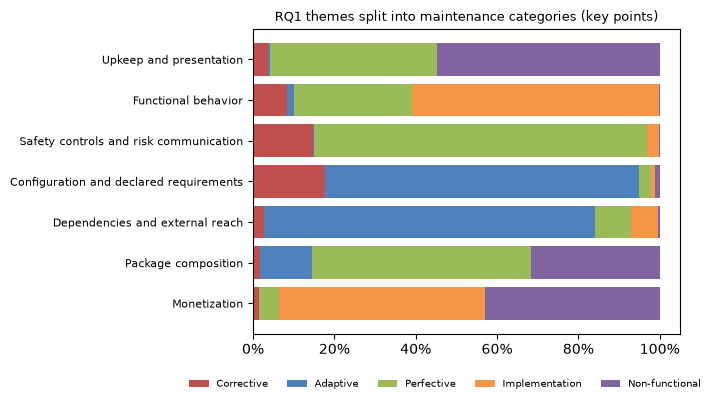

In [9]:
ct = pd.crosstab(lab["rq1_theme"], lab["category"]).reindex(columns=CATS, fill_value=0)
ct["total"] = ct.sum(axis=1)
ct = ct.sort_values("total", ascending=False)
save(ct, "rq2_theme_by_category_counts")
save(ct[CATS].div(ct["total"], axis=0), "rq2_theme_by_category_shares", fmt="{:.1%}")
save(ct[CATS].div(ct[CATS].sum(axis=0), axis=1), "rq2_category_composition", fmt="{:.1%}")

sh = ct[CATS].div(ct["total"], axis=0)
fig, ax = plt.subplots(figsize=(7, 0.45 * len(sh) + 1))
left = np.zeros(len(sh))
for c in CATS:
    ax.barh(range(len(sh)), sh[c], left=left, color=COLORS[c], label=c)
    left += sh[c].values
ax.set_yticks(range(len(sh))); ax.set_yticklabels(sh.index, fontsize=8); ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=7, ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.12))
ax.set_title("RQ1 themes split into maintenance categories (key points)", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "rq2_theme_by_category.png", dpi=200); plt.show()

In [10]:
# Corrective key points in Phase 2: which subthemes, by stratum (what kind of fixes come with a flag change)
corr = p2[p2["category"] == "Corrective"]
cs = pd.crosstab(corr["rq1_subtheme"], corr["stratum"]).reindex(columns=STRATA, fill_value=0)
cs["total"] = cs.sum(axis=1)
save(cs.sort_values("total", ascending=False), "rq2_p2_corrective_subthemes_by_stratum")

stratum,introduced,fixed,no change,total
rq1_subtheme,,,,
Metadata declarations,3,25,11,39
Code implementation changes,17,10,8,35
Safety and transparency guidance,6,14,8,28
Documentation content,3,8,12,23
Credentials and configuration values,5,11,4,20
Code-level safety checks,4,10,2,16
Personal data handling,2,9,2,13
Agent behavior guardrails,5,6,1,12
Feature and capability scope,2,2,2,6


## 5. Phase 1 vs. Phase 2

Unweighted share of pairs containing each category, within each stratum. Phase 1 was drawn balanced
(17/17/16 per round) and labelled from open codes; Phase 2 per stratum and labelled from subthemes. Large
gaps point to differences in the labelling route rather than in the population.

In [11]:
rows = []
for ph, d in lab.groupby("phase"):
    pairs = d.drop_duplicates("pair_id").set_index("pair_id")["stratum"]
    pres = pair_presence(d).loc[pairs.index]
    for s in STRATA:
        m = pairs == s
        for c in CATS:
            rows.append({"phase": ph, "stratum": s, "category": c, "share": pres.loc[m, c].mean()})
cmp = pd.DataFrame(rows).pivot_table(index=["stratum", "category"], columns="phase", values="share")
cmp["difference (p2 - p1)"] = cmp["phase 2"] - cmp["phase 1"]
cmp = cmp.reindex(pd.MultiIndex.from_product([STRATA, CATS]))
save(cmp, "rq2_p1_vs_p2", fmt="{:.1%}")

## 6. Key numbers

In [12]:
o2 = overall.loc["phase 2"]
top = share["all (weighted)"].sort_values(ascending=False)
print("Phase 2, share of pairs containing each category (weighted to ClawHub):")
for c, v in top.items():
    print(f"  {c:15s} {v:6.1%}   (dominant in {o2.loc[c, 'dominant_share']:.1%} of pairs, unweighted)")
print()
for _, r in a_all.iterrows():
    if r["q"] < ALPHA:
        direction = "more" if r["odds_ratio"] > 1 else "less"
        print(f"{r['comparison']}: {r['category']} is {direction} common "
              f"({r['share_group']:.1%} vs {r['share_baseline']:.1%}, OR {r['odds_ratio']:.2f}, q = {r['q']:.4f}; "
              f"without low-confidence q = {r['q_without_low']:.4f}; Phase 1 OR {r['phase1_odds_ratio']:.2f}, q = {r['phase1_q']:.4f})")

Phase 2, share of pairs containing each category (weighted to ClawHub):
  Perfective       60.0%   (dominant in 36.3% of pairs, unweighted)
  Non-functional   34.3%   (dominant in 12.9% of pairs, unweighted)
  Adaptive         31.7%   (dominant in 23.7% of pairs, unweighted)
  Implementation   28.4%   (dominant in 17.0% of pairs, unweighted)
  Corrective       11.4%   (dominant in 10.1% of pairs, unweighted)

introduced vs no change: Adaptive is more common (39.8% vs 28.4%, OR 1.66, q = 0.0043; without low-confidence q = 0.0230; Phase 1 OR 0.90, q = 1.0000)
fixed vs no change: Adaptive is more common (41.5% vs 28.4%, OR 1.79, q = 0.0005; without low-confidence q = 0.0005; Phase 1 OR 0.79, q = 0.6332)
fixed vs no change: Perfective is less common (51.0% vs 62.2%, OR 0.63, q = 0.0030; without low-confidence q = 0.0018; Phase 1 OR 1.72, q = 0.1175)
fixed vs no change: Implementation is less common (17.8% vs 29.4%, OR 0.52, q = 0.0005; without low-confidence q = 0.0005; Phase 1 OR 0.93, q 